
**COMPLETE COGKR VISUALIZATIONS!**

# STEP 1: Mount Drive and Setup


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Step 2: Install dependencies

In [ ]:
!pip install rdflib tqdm numpy scipy tensorboardX umap-learn plotly kaleido
!pip uninstall torch-scatter -y
!pip install torch-scatter --no-binary torch-scatter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.0/108.0 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for torch-scatter: filename=torch_scatter-2.1.2-cp312-cp312-linux_x86_64.whl size=676464 sha256=de6eeb45fa3b87dbbe9f2bf78eba2e84ba650bcc1b92204ba17dfd3a43cad03a
  Stored in directory: /root/.cache/pip/wheels/84/20/50/44800723f57cd798630e77b3ec83bc80bd26a1e3dc3a672ef5
Successfully built torch-scatter


# Extract & Verify pretrained model

In [ ]:
!unzip -o /content/drive/MyDrive/allfiles/CogKR_complete.zip -d /content/
print("✅ Setup complete!")
!ls -la /content/content/CogKR/datasets/learning_style/data/

Archive:  /content/drive/MyDrive/allfiles/CogKR_complete.zip
   creating: /content/content/CogKR/
   creating: /content/content/CogKR/src/
  inflating: /content/content/CogKR/src/preprocess.py  
  inflating: /content/content/CogKR/src/torch_utils.py  
  inflating: /content/content/CogKR/src/parse_args.py  
  inflating: /content/content/CogKR/src/main.py  
  inflating: /content/content/CogKR/src/module.py  
  inflating: /content/content/CogKR/src/inverse_model.ipynb  
   creating: /content/content/CogKR/src/__pycache__/
  inflating: /content/content/CogKR/src/__pycache__/evaluation.cpython-312.pyc  
  inflating: /content/content/CogKR/src/__pycache__/torch_utils.cpython-312.pyc  
  inflating: /content/content/CogKR/src/__pycache__/parse_args.cpython-312.pyc  
  inflating: /content/content/CogKR/src/__pycache__/grapher.cpython-312.pyc  
  inflating: /content/content/CogKR/src/__pycache__/utils.cpython-312.pyc  
  inflating: /content/content/CogKR/src/__pycache__/trainer.cpython-312.pyc  

# STEP 3: Imports

In [ ]:
import torch
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')
import umap
import plotly.express as px
import plotly.graph_objects as go

print("Libraries imported!")

Libraries imported!


# STEP 4: Load Model and Mappings

In [ ]:
# Update base_dir to the correct path after extraction
base_dir = "/content/content/CogKR"
state_file = os.path.join(base_dir, "datasets/learning_style/log/04-07-17-5-32-direct-True-checkpointed_run/best.state")
ent2id_file = os.path.join(base_dir, "datasets/learning_style/data/ent2id.txt")
rel2id_file = os.path.join(base_dir, "datasets/learning_style/data/relation2id.txt")

# Check if files exist before loading
print(f"Checking file paths...")
print(f"ent2id_file exists: {os.path.exists(ent2id_file)}")
print(f"rel2id_file exists: {os.path.exists(rel2id_file)}")
print(f"state_file exists: {os.path.exists(state_file)}")

# Load entity mappings
ent2id = {}
if os.path.exists(ent2id_file):
    with open(ent2id_file, "r") as f:
        for line in f:
            idx, name = line.strip().split("\t")
            ent2id[name] = int(idx)
    print(f"Loaded {len(ent2id)} entities")
else:
    print("ent2id.txt not found!")

# Load relation mappings
rel2id = {}
if os.path.exists(rel2id_file):
    with open(rel2id_file, "r") as f:
        for line in f:
            idx, uri = line.strip().split("\t")
            rel2id[uri] = int(idx)
    print(f"Loaded {len(rel2id)} relations")
else:
    print("relation2id.txt not found!")

# Create reverse mappings
id2ent = {v: k for k, v in ent2id.items()}
id2rel = {v: k for k, v in rel2id.items()}

# Load embeddings
if os.path.exists(state_file):
    state = torch.load(state_file, map_location="cpu")
    model_state = state["model"]
    entity_embed = model_state["entity_embeddings.weight"].detach().cpu().numpy()
    relation_embed = model_state["relation_embeddings.weight"].detach().cpu().numpy()
    print(f"Entity embeddings shape: {entity_embed.shape}")
    print(f"Relation embeddings shape: {relation_embed.shape}")
else:
    print("best.state not found!")
    # Create dummy embeddings for testing if file not found
    entity_embed = np.random.randn(len(ent2id), 50)
    relation_embed = np.random.randn(len(rel2id), 50)
    print("Using random dummy embeddings for testing")


Checking file paths...
ent2id_file exists: True
rel2id_file exists: True
state_file exists: True
Loaded 752 entities
Loaded 132 relations
Entity embeddings shape: (753, 50)
Relation embeddings shape: (134, 50)


# STEP 5: TEST

In [ ]:
!python /content/drive/MyDrive/allfiles/CogKR_complete/content/CogKR/src/main.py --inference --directory /content/drive/MyDrive/allfiles/CogKR_complete/content/CogKR/datasets/learning_style --gpu -1 --config /content/drive/MyDrive/allfiles/CogKR_complete/content/CogKR/configs/learning_style_cpu.json --load_state /content/drive/MyDrive/allfiles/CogKR_complete/content/CogKR/datasets/learning_style/log/04-07-17-5-32-direct-True-checkpointed_run/best.state

{'trainer': {'evaluate_inverse': False, 'weighted_sample': True, 'ignore_onehop': False, 'meta_learn': False, 'sample_weight': 1.0, 'rollout_num': 1, 'test_rollout_num': 1}, 'train': {'entropy_beta': 0.05, 'validate_metric': 'MAP', 'max_steps': 5000, 'batch_size': 64, 'test_batch_size': 128, 'log_interval': 50, 'evaluate_interval': 100}, 'pretrain': {'keep_embed': False, 'log_interval': 1000, 'evaluate_interval': 10000, 'batch_size': 64}, 'model': {'message': True, 'entity_embed': True, 'max_steps': 5, 'max_nodes': 200, 'max_neighbors': 10, 'embed_size': 50, 'hidden_size': 100, 'topk': 32, 'reward_policy': 'direct', 'baseline_lambda': 0.05}, 'sparse_embed': False, 'optimizer': {'scheduler': {'factor': 0.3, 'patience': 10, 'min_lr': 1e-06}, 'name': 'Adam', 'embed': {'lr': 0.001}, 'summary': {'lr': 0.0001}, 'agent': {'lr': 0.001}, 'config': {'weight_decay': 0.0001}}, 'dataset': 'learning_style', 'embedding_dim': 50, 'batch_size': 64, 'max_epochs': 100, 'learning_rate': 0.001, 'num_worker

# STEP 6: PREDICTION FUNCTION

In [ ]:
def get_top_k_answers(student_name, relation_uri, k=5):
    """Return top-k answer codes for a student and question."""
    if student_name not in ent2id:
        return []

    student_id = ent2id[student_name]
    rel_id = rel2id.get(relation_uri, 0)
    query = entity_embed[student_id] + relation_embed[rel_id]
    scores = np.dot(entity_embed, query)

    valid_idx = [i for i in range(len(ent2id))
                 if i != student_id and not id2ent[i].startswith('s')]

    if not valid_idx:
        return []

    answer_scores = scores[valid_idx]
    top_indices = np.argsort(answer_scores)[::-1][:k]
    top_ids = [valid_idx[i] for i in top_indices]

    return [id2ent[idx] for idx in top_ids]

# VISUALIZATION 1: Hit@k Metrics Bar Chart

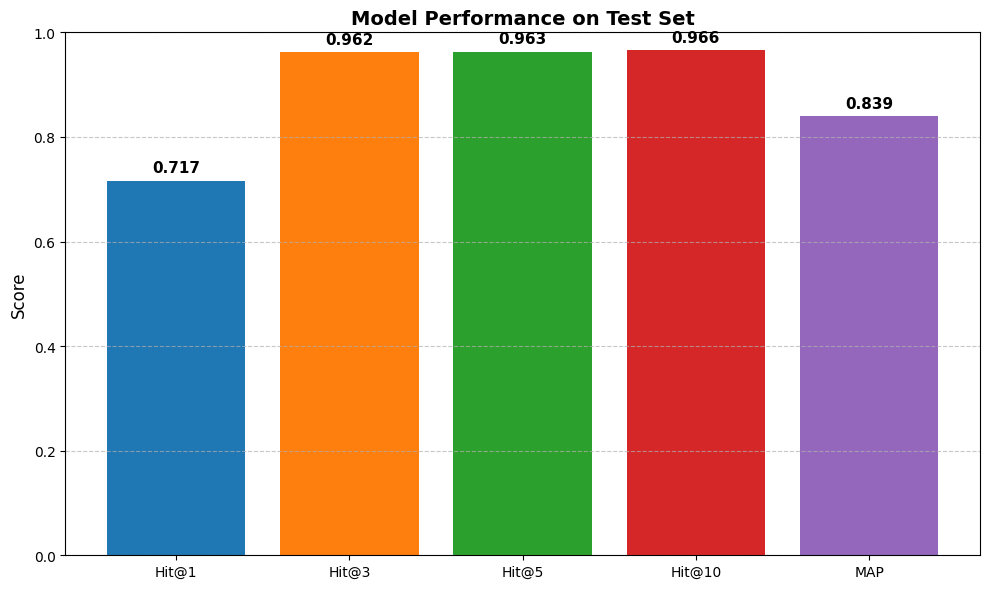

Saved 'hitk_metrics.png'


In [ ]:
# Metrics from your test evaluation
metrics = ['Hit@1', 'Hit@3', 'Hit@5', 'Hit@10', 'MAP']
values = [0.7166, 0.9618, 0.9633, 0.9662, 0.8394]

# Create bar chart
plt.figure(figsize=(10, 6))
bars = plt.bar(metrics, values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'])
plt.ylim(0, 1)
plt.ylabel('Score', fontsize=12)
plt.title('Model Performance on Test Set', fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels on top of bars
for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('hitk_metrics.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved 'hitk_metrics.png'")

# VISUALIZATION 2: Entity Embeddings UMAP



VISUALIZATION 2: Entity Embeddings UMAP
Saved 'entity_embeddings_umap.html'
PNG export skipped. HTML version saved.


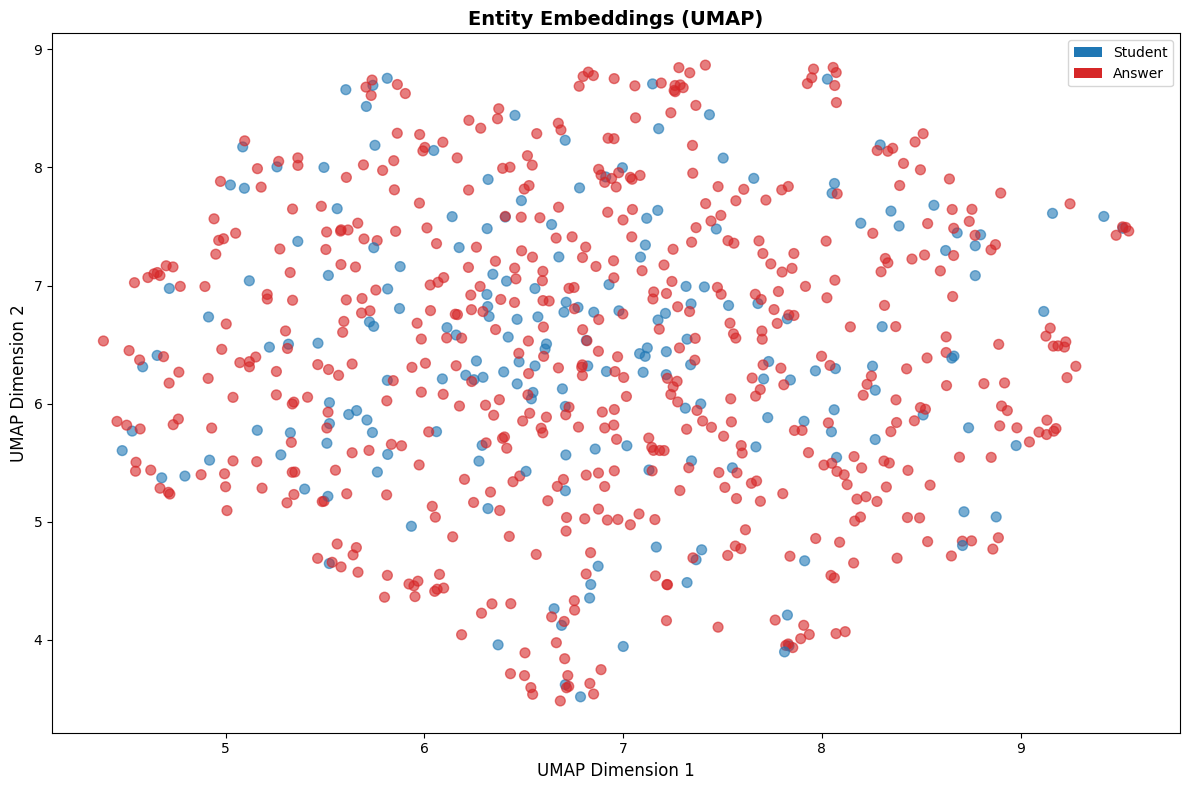

Saved 'entity_embeddings_umap_static.png'


In [ ]:
print("\n" + "="*70)
print("VISUALIZATION 2: Entity Embeddings UMAP")
print("="*70)

if len(ent2id) > 0:
    # Remove padding (entity_embed may have one extra row)
    entity_embed_no_pad = entity_embed[:len(ent2id)]

    # Apply UMAP dimensionality reduction
    reducer = umap.UMAP(n_components=2, random_state=42)
    emb_2d = reducer.fit_transform(entity_embed_no_pad)

    # dataframe
    entity_names = [id2ent[i] for i in range(len(ent2id))]
    is_student = [name.startswith('s') for name in entity_names]

    df_umap = pd.DataFrame({
        'x': emb_2d[:, 0],
        'y': emb_2d[:, 1],
        'label': entity_names,
        'type': ['Student' if s else 'Answer' for s in is_student]
    })

    # interactive Plotly visualization
    fig = px.scatter(df_umap, x='x', y='y', text='label', color='type',
                     hover_data={'label': True},
                     title='Entity Embeddings Visualization (UMAP)',
                     color_discrete_map={'Student': '#1f77b4', 'Answer': '#d62728'})

    fig.update_traces(textposition='top center', marker=dict(size=8, opacity=0.7))
    fig.update_layout(width=1000, height=700, font=dict(size=12))

    # Save as HTML
    fig.write_html('entity_embeddings_umap.html')
    print("Saved 'entity_embeddings_umap.html'")

    # save as PNG
    try:
        fig.write_image('entity_embeddings_umap.png', width=1000, height=700)
        print("Saved 'entity_embeddings_umap.png'")
    except:
        print("PNG export skipped. HTML version saved.")

    fig.show()

    # Static matplotlib version
    plt.figure(figsize=(12, 8))
    colors = ['#1f77b4' if s else '#d62728' for s in is_student]
    plt.scatter(emb_2d[:, 0], emb_2d[:, 1], c=colors, alpha=0.6, s=50)
    plt.xlabel('UMAP Dimension 1', fontsize=12)
    plt.ylabel('UMAP Dimension 2', fontsize=12)
    plt.title('Entity Embeddings (UMAP)', fontsize=14, fontweight='bold')

    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#1f77b4', label='Student'),
                       Patch(facecolor='#d62728', label='Answer')]
    plt.legend(handles=legend_elements, loc='upper right')

    plt.tight_layout()
    plt.savefig('entity_embeddings_umap_static.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved 'entity_embeddings_umap_static.png'")
else:
    print("No entities loaded. Skipping UMAP visualization.")


In [ ]:
# ---- Standard FSLSM mapping ----
# Dimensions and their poles
DIMENSIONS = {
    'Active/Reflective': ('Active', 'Reflective'),
    'Sensing/Intuitive': ('Sensing', 'Intuitive'),
    'Visual/Verbal': ('Visual', 'Verbal'),
    'Sequential/Global': ('Sequential', 'Global'),
}

# Question groups per dimension (order from the FSLSM index)
DIM_QUESTIONS = {
    'Active/Reflective': [1,5,9,13,17,21,25,29,33,37,41],
    'Sensing/Intuitive': [2,6,10,14,18,22,26,30,34,38,42],
    'Visual/Verbal': [3,7,11,15,19,23,27,31,35,39,43],
    'Sequential/Global': [4,8,12,16,20,24,28,32,36,40,44],
}

# Build answer-to-label mapping
ANSWER_TO_LABEL = {}

for dim, q_list in DIM_QUESTIONS.items():
    first_pole, second_pole = DIMENSIONS[dim]
    for idx, q_num in enumerate(q_list):  # idx = 0,1,2,... for each dimension
        if (idx + 1) % 2 == 1:  # odd position: A -> first pole, B -> second
            label_a, label_b = first_pole, second_pole
        else:                   # even position: A -> second, B -> first
            label_a, label_b = second_pole, first_pole
        ANSWER_TO_LABEL[f'A{q_num}'] = label_a
        ANSWER_TO_LABEL[f'B{q_num}'] = label_b

def get_answer_meaning(code):
    # code is like "A1" or "B3"
    return ANSWER_TO_LABEL.get(code, f"Answer {code}")

In [ ]:
print(get_answer_meaning('A1'))   # -> Active
print(get_answer_meaning('B1'))   # -> Reflective
print(get_answer_meaning('A2'))   # -> Sensing
print(get_answer_meaning('B2'))   # -> Intuitive
print(get_answer_meaning('A3'))   # -> Visual
print(get_answer_meaning('B3'))   # -> Verbal

Active
Reflective
Sensing
Intuitive
Visual
Verbal


# VISUALIZATION 3: Cognitive Graphs for Different Students

In [ ]:
!pip install plotly kaleido

Loaded 6600 triples from all_triples.txt
Using relation IDs 0-43 as the 44 FSLSM questions.
Found 195 students.

--- Analyzing Student: s0 (ID: 0) ---

COGNITIVE PROFILE FOR s0
  Active      : -0.1697  (based on 6 answers)
  Reflective  : -0.3610  (based on 5 answers)
  Sensing     : 0.1608  (based on 6 answers)
  Intuitive   : -0.0684  (based on 4 answers)
  Visual      : 0.2584  (based on 6 answers)
  Verbal      : 0.1976  (based on 5 answers)
  Sequential  : 0.0379  (based on 6 answers)
  Global      : -0.0966  (based on 5 answers)

--- Dominant Learning Style ---
  Active/Reflective   : Active (score: -0.1697)
  Sensing/Intuitive   : Sensing (score: 0.1608)
  Visual/Verbal       : Visual (score: 0.2584)
  Sequential/Global   : Sequential (score: 0.0379)


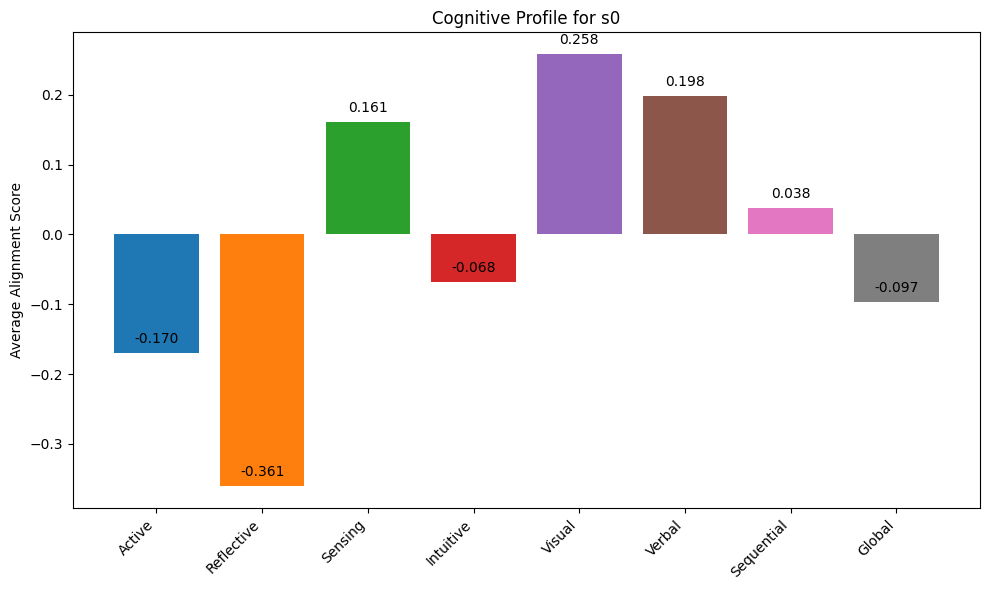


CLASS SUMMARY (First 5 Students)
Student Active/Reflective Sensing/Intuitive Visual/Verbal Sequential/Global
     s0            Active           Sensing        Visual        Sequential
     s1            Active           Sensing        Verbal        Sequential
     s2            Active           Sensing        Verbal        Sequential
     s3            Active         Intuitive        Verbal            Global
     s4            Active         Intuitive        Verbal        Sequential


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re

# ============================================================================
# 1. LOAD ALL TRIPLES FROM all_triples.txt
# ============================================================================

base_dir = "/content/drive/MyDrive/allfiles/CogKR_complete/content/CogKR/datasets/learning_style/data"
all_triples_file = os.path.join(base_dir, "all_triples.txt")

def load_all_triples():
    triples = {}
    if not os.path.exists(all_triples_file):
        print(f"Error: {all_triples_file} not found.")
        return triples
    with open(all_triples_file, 'r') as f:
        for line in f:
            parts = line.strip().split('\t')
            if len(parts) >= 3:
                head_id = int(parts[0])
                rel_id = int(parts[1])
                tail_id = int(parts[2])
                triples[(head_id, rel_id)] = tail_id
    print(f"Loaded {len(triples)} triples from all_triples.txt")
    return triples

# ============================================================================
# 2. LOAD ENTITY AND RELATION MAPPINGS (if not already loaded)
# ============================================================================

if 'ent2id' not in globals():
    ent2id = {}
    ent2id_file = os.path.join(base_dir, "ent2id.txt")
    with open(ent2id_file, 'r') as f:
        for line in f:
            idx, name = line.strip().split('\t')
            ent2id[name] = int(idx)
    id2ent = {v: k for k, v in ent2id.items()}

if 'rel2id' not in globals():
    rel2id = {}
    rel2id_file = os.path.join(base_dir, "relation2id.txt")
    with open(rel2id_file, 'r') as f:
        for line in f:
            idx, name = line.strip().split('\t')
            rel2id[name] = int(idx)
    id2rel = {v: k for k, v in rel2id.items()}

# ============================================================================
# 3. FSLSM MAPPING
# ============================================================================

DIMENSIONS = {
    'Active/Reflective': ('Active', 'Reflective'),
    'Sensing/Intuitive': ('Sensing', 'Intuitive'),
    'Visual/Verbal': ('Visual', 'Verbal'),
    'Sequential/Global': ('Sequential', 'Global'),
}

DIM_QUESTIONS = {
    'Active/Reflective': [1,5,9,13,17,21,25,29,33,37,41],
    'Sensing/Intuitive': [2,6,10,14,18,22,26,30,34,38,42],
    'Visual/Verbal': [3,7,11,15,19,23,27,31,35,39,43],
    'Sequential/Global': [4,8,12,16,20,24,28,32,36,40,44],
}

ANSWER_TO_LABEL = {}
for dim, q_list in DIM_QUESTIONS.items():
    first_pole, second_pole = DIMENSIONS[dim]
    for idx, q_num in enumerate(q_list):
        if (idx + 1) % 2 == 1:
            label_a, label_b = first_pole, second_pole
        else:
            label_a, label_b = second_pole, first_pole
        ANSWER_TO_LABEL[f'A{q_num}'] = label_a
        ANSWER_TO_LABEL[f'B{q_num}'] = label_b

# ============================================================================
# 4. COMPUTE PROFILE FOR A GIVEN STUDENT
# ============================================================================

def compute_profile(student_id, triples, question_rel_ids):
    pole_scores = {p: 0.0 for p in ['Active','Reflective','Sensing','Intuitive',
                                    'Visual','Verbal','Sequential','Global']}
    pole_counts = {p: 0 for p in pole_scores}

    for rel_id in question_rel_ids:
        ans_id = triples.get((student_id, rel_id))
        if ans_id is None:
            continue
        ans_name = id2ent.get(ans_id)
        if ans_name is None:
            continue
        label = ANSWER_TO_LABEL.get(ans_name)
        if label is None:
            continue

        student_embed = entity_embed[student_id]
        rel_embed = relation_embed[rel_id]
        ans_embed = entity_embed[ans_id]
        query = student_embed + rel_embed
        score = np.dot(ans_embed, query)

        pole_scores[label] += score
        pole_counts[label] += 1

    # Normalize by count
    for p in pole_scores:
        if pole_counts[p] > 0:
            pole_scores[p] /= pole_counts[p]
    return pole_scores, pole_counts

# ============================================================================
# 5. MAIN EXECUTION
# ============================================================================

triples = load_all_triples()
if not triples:
    exit()

# The first 44 relations are the FSLSM questions (IDs 0..43)
question_rel_ids = list(range(44))
print(f"Using relation IDs 0-43 as the 44 FSLSM questions.")

# Get all student IDs (entities whose name starts with 's')
student_ids = [idx for idx, name in id2ent.items() if name.startswith('s')]
print(f"Found {len(student_ids)} students.")

# Analyze first student
test_id = student_ids[0]
test_name = id2ent[test_id]
print(f"\n--- Analyzing Student: {test_name} (ID: {test_id}) ---")

scores, counts = compute_profile(test_id, triples, question_rel_ids)

print("\n" + "="*60)
print(f"COGNITIVE PROFILE FOR {test_name}")
print("="*60)
for p in scores:
    print(f"  {p:12s}: {scores[p]:.4f}  (based on {counts[p]} answers)")

# Dominant styles
print("\n--- Dominant Learning Style ---")
for dim, (p1, p2) in DIMENSIONS.items():
    s1 = scores[p1]
    s2 = scores[p2]
    dominant = p1 if s1 >= s2 else p2
    print(f"  {dim:20s}: {dominant} (score: {max(s1,s2):.4f})")

# Plot
plt.figure(figsize=(10,6))
poles = list(scores.keys())
values = list(scores.values())
colors = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f']
bars = plt.bar(poles, values, color=colors)
plt.ylabel('Average Alignment Score')
plt.title(f'Cognitive Profile for {test_name}')
plt.xticks(rotation=45, ha='right')
for bar, val in zip(bars, values):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
             f'{val:.3f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

# ============================================================================
# 6. CLASS SUMMARY (first 5 students)
# ============================================================================
print("\n" + "="*60)
print("CLASS SUMMARY (First 5 Students)")
print("="*60)
report = []
for sid in student_ids[:5]:
    sname = id2ent[sid]
    sc, _ = compute_profile(sid, triples, question_rel_ids)
    row = {'Student': sname}
    for dim, (p1, p2) in DIMENSIONS.items():
        row[dim] = p1 if sc[p1] >= sc[p2] else p2
    report.append(row)
if report:
    print(pd.DataFrame(report).to_string(index=False))

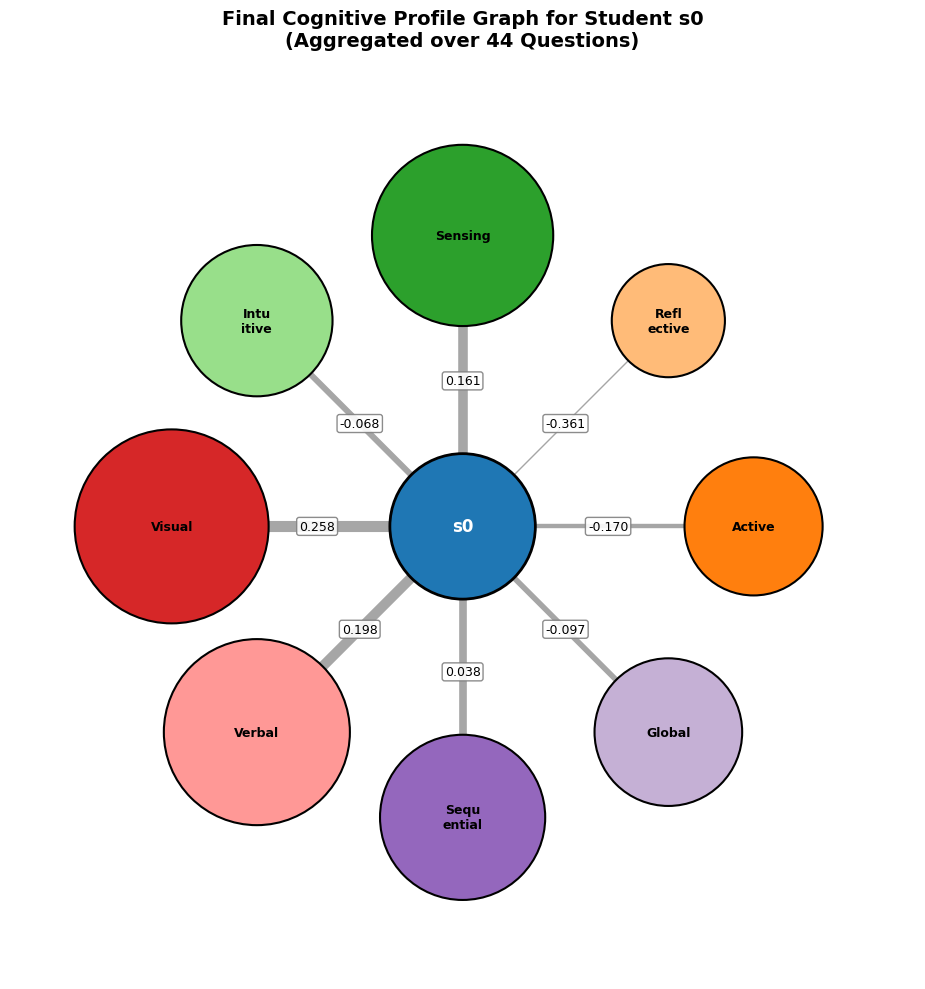

Saved 'final_cognitive_profile_graph_s0.png'


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def draw_final_profile_graph(student_name, pole_scores, ax=None, title=None):
    """
    Draws a cognitive graph summarizing the final learned profile.
    Center = Student, Surrounding nodes = FSLSM Poles, Edges = Final Scores.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 9))

    # Prepare data
    poles = list(pole_scores.keys())
    scores = list(pole_scores.values())

    # Normalize scores for edge thickness (map to 1.0 - 6.0 linewidth)
    min_score = min(scores)
    max_score = max(scores)
    if max_score > min_score:
        norm_scores = [(s - min_score) / (max_score - min_score) for s in scores]
    else:
        norm_scores = [0.5] * len(scores)

    # Position nodes in a circle
    num_nodes = len(poles)
    angles = np.linspace(0, 2 * np.pi, num_nodes, endpoint=False)
    radius = 1.8

    # --- 1. Draw Edges (from Center to Poles) ---
    for i, (pole, score, norm) in enumerate(zip(poles, scores, norm_scores)):
        angle = angles[i]
        x2 = radius * np.cos(angle)
        y2 = radius * np.sin(angle)

        # Line thickness from 1 to 8
        linewidth = 1 + norm * 7
        ax.plot([0, x2], [0, y2], 'gray', linewidth=linewidth, alpha=0.7, zorder=1)

        # Put the numerical score in the middle of the edge
        mx, my = x2/2, y2/2
        ax.text(mx, my, f'{score:.3f}', fontsize=9, ha='center', va='center',
                bbox=dict(boxstyle="round,pad=0.2", facecolor='white', alpha=0.9, edgecolor='gray'))

    # --- 2. Draw Center Node (The Student) ---
    student_circle = plt.Circle((0, 0), 0.45, color='#1f77b4', ec='black', linewidth=2, zorder=2)
    ax.add_patch(student_circle)
    ax.text(0, 0, student_name, ha='center', va='center', fontsize=12, fontweight='bold', color='white')

    # --- 3. Draw Surrounding Nodes (The FSLSM Poles) ---
    # Color map for the poles
    color_map = {
        'Active': '#ff7f0e', 'Reflective': '#ffbb78',
        'Sensing': '#2ca02c', 'Intuitive': '#98df8a',
        'Visual': '#d62728', 'Verbal': '#ff9896',
        'Sequential': '#9467bd', 'Global': '#c5b0d5'
    }

    for i, (pole, score, norm) in enumerate(zip(poles, scores, norm_scores)):
        angle = angles[i]
        x = radius * np.cos(angle)
        y = radius * np.sin(angle)

        size = 0.35 + norm * 0.25  # Node size varies with score
        color = color_map.get(pole, '#17becf')

        node_circle = plt.Circle((x, y), size, color=color, ec='black', linewidth=1.5, zorder=2)
        ax.add_patch(node_circle)

        # Pole name inside the node (split into two lines if long)
        label = pole
        if len(label) > 7:
            label = label[:4] + '\n' + label[4:]
        ax.text(x, y, label, ha='center', va='center', fontsize=9, fontweight='bold', color='black')

    ax.set_xlim(-2.8, 2.8)
    ax.set_ylim(-2.8, 2.8)
    ax.set_aspect('equal')
    ax.axis('off')

    if title:
        ax.set_title(title, fontsize=14, fontweight='bold', pad=20)

    return ax

# =====================================================
# RUN THIS TO GENERATE THE FINAL PROFILE GRAPH
# =====================================================

# Assuming 'pole_scores' is the dictionary you computed earlier (contains Active: -0.1697, etc.)
# If you lost it, just recompute it using the functions from the previous step.

# Example: If you have the scores stored for s0
if 'scores_s0' not in locals():
    # Recompute quickly if needed (assuming triples and entity_embed are loaded)
    scores_s0, _ = compute_profile(0, triples, list(range(44)))
# The 'else' block which caused the NameError is removed as 'scores_s0' is either newly computed
# or already available from a previous cell execution.

# Draw the final profile graph
fig, ax = plt.subplots(figsize=(10, 10))
draw_final_profile_graph('s0', scores_s0, ax=ax,
                         title=f"Final Cognitive Profile Graph for Student s0\n(Aggregated over 44 Questions)")

plt.tight_layout()
plt.savefig('final_cognitive_profile_graph_s0.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved 'final_cognitive_profile_graph_s0.png'")

In [ ]:
import networkx as nx
import plotly.graph_objects as go
import numpy as np

def create_clean_cognitive_graph(student_name, pole_scores, filename=None):
    """
    Clean, elegant cognitive graph with larger, readable nodes.
    Node size increased 3x, and spacing adjusted to prevent overlap.
    """

    # Convert to Python floats
    pole_scores = {k: float(v) for k, v in pole_scores.items()}

    # --- 1. Color palette ---
    color_palette = {
        'Active': '#EA4335',
        'Reflective': '#FBBC04',
        'Sensing': '#34A853',
        'Intuitive': '#A8D5BA',
        'Visual': '#FF6D01',
        'Verbal': '#F6C6EA',
        'Sequential': '#6C5B7B',
        'Global': '#A8A8A8'
    }

    # --- 2. Position nodes with extra spacing ---
    all_scores = list(pole_scores.values())
    max_abs = max(abs(s) for s in all_scores) if all_scores else 1.0

    pos = {}
    pos['center'] = np.array([-0.2, 0.0])  # student slightly offset

    positive_poles = [(p, s) for p, s in pole_scores.items() if s >= 0]
    negative_poles = [(p, s) for p, s in pole_scores.items() if s < 0]
    positive_poles.sort(key=lambda x: x[1], reverse=True)
    negative_poles.sort(key=lambda x: abs(x[1]), reverse=True)

    # Increase radius range to prevent overlap
    min_radius = 1.2   # increased from 0.8
    max_radius = 3.0   # increased from 2.0

    if positive_poles:
        n = len(positive_poles)
        for i, (pole, score) in enumerate(positive_poles):
            norm_dist = abs(score) / max_abs
            distance = min_radius + (max_radius - min_radius) * (1 - norm_dist)
            angle = np.radians(-30 + (i / (n - 1)) * 60) if n > 1 else 0
            x = distance * np.cos(angle) + pos['center'][0]
            y = distance * np.sin(angle)
            pos[pole] = np.array([x, y])

    if negative_poles:
        n = len(negative_poles)
        for i, (pole, score) in enumerate(negative_poles):
            norm_dist = abs(score) / max_abs
            distance = min_radius + (max_radius - min_radius) * norm_dist
            angle = np.radians(120 + (i / (n - 1)) * 120) if n > 1 else np.pi
            x = distance * np.cos(angle) + pos['center'][0]
            y = distance * np.sin(angle)
            pos[pole] = np.array([x, y])

    # --- 3. Build graph ---
    G = nx.Graph()
    G.add_node('center', label=student_name, type='student', color='#1a73e8', size=108)

    for pole, score in pole_scores.items():
        G.add_node(pole,
                   label=pole,
                   score=score,
                   color=color_palette.get(pole, '#17becf'),
                   size=84)
        G.add_edge('center', pole,
                   score=score,
                   is_positive=score >= 0,
                   weight=0.8 + (abs(score) / max_abs) * 1.5,
                   label=f"{score:.3f}")

    # --- 4. Nodes ---
    node_x, node_y, node_text, node_color, node_size = [], [], [], [], []
    node_labels = []

    for node in G.nodes():
        x, y = pos[node]
        node_x.append(x); node_y.append(y)
        data = G.nodes[node]
        node_labels.append(data['label'])

        if data.get('type') == 'student':
            text = f"<b>{data['label']}</b><br><i>Student</i>"
            size = 108
        else:
            text = (f"<b>{data['label']}</b><br>"
                    f"Score: {data['score']:.4f}")
            size = 84
        node_text.append(text)
        node_color.append(data['color'])
        node_size.append(size)

    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode='markers+text',
        text=node_labels,
        textposition='middle center',
        textfont=dict(size=18, color='white'),
        hovertext=node_text,
        hoverinfo='text',
        marker=dict(
            size=node_size,
            color=node_color,
            line=dict(width=2, color='white'),
            opacity=0.9,
            symbol='circle'
        ),
        showlegend=False
    )

    # --- 5. Edges ---
    edge_traces = []
    edge_label_x, edge_label_y, edge_label_text = [], [], []

    for u, v, data in G.edges(data=True):
        x0, y0 = pos[u]; x1, y1 = pos[v]
        if data['is_positive']:
            dash = 'solid'
            color = '#2E7D32'
        else:
            dash = 'dash'
            color = '#C62828'

        edge_traces.append(go.Scatter(
            x=[x0, x1], y=[y0, y1],
            mode='lines',
            line=dict(width=data['weight'], color=color, dash=dash),
            hoverinfo='none',
            showlegend=False
        ))

        mx = (x0 + x1) * 0.5
        my = (y0 + y1) * 0.5
        edge_label_x.append(mx); edge_label_y.append(my)
        edge_label_text.append(data['label'])

    label_trace = go.Scatter(
        x=edge_label_x, y=edge_label_y,
        mode='text',
        text=edge_label_text,
        textfont=dict(size=14, color='#333333'),
        textposition='middle center',
        hoverinfo='none',
        showlegend=False
    )

    # --- 6. Legend ---
    legend_items = []
    for i, (pole, color) in enumerate(color_palette.items()):
        legend_items.append(
            dict(
                x=0.88, y=0.90 - i*0.065,
                xref='paper', yref='paper',
                text=f"<span style='background:{color};color:white;padding:2px 14px;border-radius:10px;font-size:13px;'>{pole}</span>",
                showarrow=False,
                font=dict(size=13)
            )
        )

    legend_items.append(
        dict(
            x=0.88, y=0.38,
            xref='paper', yref='paper',
            text="<span style='color:#2E7D32;font-size:13px;'>── Positive (solid)</span>",
            showarrow=False,
            font=dict(size=13)
        )
    )
    legend_items.append(
        dict(
            x=0.88, y=0.33,
            xref='paper', yref='paper',
            text="<span style='color:#C62828;font-size:13px;'>- - - Negative (dashed)</span>",
            showarrow=False,
            font=dict(size=13)
        )
    )

    # --- 7. Figure with larger range to fit nodes ---
    fig = go.Figure(
        data=edge_traces + [node_trace, label_trace],
        layout=go.Layout(
            title=dict(
                text=f"🧠 <b>Cognitive Profile</b><br>"
                     f"<span style='font-size:16px;font-weight:normal;'>Student {student_name}</span>",
                font=dict(size=24),
                y=0.95
            ),
            showlegend=False,
            hovermode='closest',
            margin=dict(l=40, r=40, t=80, b=40),
            xaxis=dict(
                showgrid=False, zeroline=False, showticklabels=False,
                range=[-4.0, 4.0]  # Increased range
            ),
            yaxis=dict(
                showgrid=False, zeroline=False, showticklabels=False,
                range=[-3.5, 3.5]  # Increased range
            ),
            width=1100,
            height=950,
            annotations=[
                dict(
                    x=0.5, y=-0.06,
                    xref='paper', yref='paper',
                    text="<i style='font-size:14px;'>Positive scores (solid) closer • Negative scores (dashed) farther</i>",
                    showarrow=False,
                    font=dict(size=14, color='gray')
                )
            ] + legend_items,
            paper_bgcolor='#fafafa',
            plot_bgcolor='#fafafa',
            font=dict(family='Arial, Helvetica, sans-serif')
        )
    )

    # --- 8. Save and display ---
    if filename is None:
        filename = f'cognitive_profile_{student_name}.html'

    fig.write_html(filename)
    print(f"✅ Interactive graph saved as '{filename}'")

    fig.show()
    return fig

# ============================================================
# RUN
# ============================================================
if 'scores_s0' not in locals():
    scores_s0, _ = compute_profile(0, triples, list(range(44)))

fig = create_clean_cognitive_graph('s0', scores_s0)

✅ Interactive graph saved as 'cognitive_profile_s0.html'


In [ ]:
# ============================================================
# GENERATE JOINT COGNITIVE GRAPH FOR THE ENTIRE CLASS
# ============================================================

def compute_class_profile(student_ids, triples, question_rel_ids):
    """
    Computes the average cognitive profile across all students in the class.
    Returns a single dictionary of average scores for each of the 8 poles.
    """
    # Initialize accumulators
    total_scores = {
        'Active': 0.0, 'Reflective': 0.0,
        'Sensing': 0.0, 'Intuitive': 0.0,
        'Visual': 0.0, 'Verbal': 0.0,
        'Sequential': 0.0, 'Global': 0.0,
    }
    total_counts = {k: 0 for k in total_scores}
    valid_students = 0

    for sid in student_ids:
        scores, counts = compute_profile(sid, triples, question_rel_ids)
        if scores is None:
            continue

        valid_students += 1
        for pole in scores:
            total_scores[pole] += scores[pole]
            total_counts[pole] += counts[pole]

    if valid_students == 0:
        print("No valid student profiles found.")
        return None

    # Compute averages
    avg_scores = {}
    for pole in total_scores:
        if total_counts[pole] > 0:
            avg_scores[pole] = total_scores[pole] / total_counts[pole]
        else:
            avg_scores[pole] = 0.0

    print(f"✅ Aggregated {valid_students} students into a single class profile.")
    return avg_scores

# ============================================================
# RUN: Generate the Joint Class Cognitive Graph
# ============================================================

# Get all student IDs (entities starting with 's')
all_student_ids = [idx for idx, name in id2ent.items() if name.startswith('s')]
print(f"Total students found: {len(all_student_ids)}")

# Compute the class average profile
class_profile = compute_class_profile(all_student_ids, triples, list(range(44)))

if class_profile:
    # Create the joint graph
    # We label the center node as the class name
    class_name = f"Class (n={len(all_student_ids)})"
    fig = create_clean_cognitive_graph(class_name, class_profile)

    # Optional: Print the class averages
    print("\n--- Class Average Cognitive Profile ---")
    for pole, score in class_profile.items():
        print(f"  {pole:12s}: {score:.4f}")

Total students found: 195
✅ Aggregated 195 students into a single class profile.
✅ Interactive graph saved as 'cognitive_profile_Class (n=195).html'



--- Class Average Cognitive Profile ---
  Active      : -0.0097
  Reflective  : -0.0504
  Sensing     : 0.0115
  Intuitive   : 0.0164
  Visual      : -0.0014
  Verbal      : 0.0142
  Sequential  : 0.0099
  Global      : -0.0093


In [ ]:
import networkx as nx
import plotly.graph_objects as go
import numpy as np

def get_dominant_pole(scores):
    """Return the pole with the highest score (dominant learning style)."""
    # In case of ties, pick first (deterministic)
    return max(scores, key=lambda p: (scores[p], p))

def create_class_joint_graph(student_ids, triples, question_rel_ids, filename=None):
    """
    Builds a graph with all students connected to their dominant pole.
    - 8 large pole nodes (colored)
    - 195 student nodes (small, colored by their dominant pole)
    - Edges from student to pole
    """

    # --- 1. Compute dominant pole for each student ---
    student_poles = {}
    pole_counts = {p: 0 for p in ['Active', 'Reflective', 'Sensing', 'Intuitive',
                                  'Visual', 'Verbal', 'Sequential', 'Global']}

    for sid in student_ids:
        scores, _ = compute_profile(sid, triples, question_rel_ids)
        if scores is None:
            continue
        dominant = get_dominant_pole(scores)
        student_poles[sid] = dominant
        pole_counts[dominant] += 1

    print(f"Processed {len(student_poles)} students.")
    print("Pole counts:", pole_counts)

    # --- 2. Build NetworkX graph ---
    G = nx.Graph()

    # Add pole nodes (large)
    color_map = {
        'Active': '#EA4335', 'Reflective': '#FBBC04',
        'Sensing': '#34A853', 'Intuitive': '#A8D5BA',
        'Visual': '#FF6D01', 'Verbal': '#F6C6EA',
        'Sequential': '#6C5B7B', 'Global': '#A8A8A8'
    }

    for pole, count in pole_counts.items():
        G.add_node(pole,
                   label=pole,
                   type='pole',
                   color=color_map[pole],
                   size=50 + count * 0.3,  # size proportional to count
                   count=count)

    # Add student nodes (small, colored by pole)
    for sid, pole in student_poles.items():
        sname = id2ent[sid]
        G.add_node(sid,
                   label=sname,
                   type='student',
                   color=color_map[pole],
                   size=10,
                   pole=pole)
        G.add_edge(sid, pole, weight=0.5)  # thin lines

    # --- 3. Layout: Force-directed (spring) ---
    # Use a layout that spreads nodes nicely
    pos = nx.spring_layout(G, seed=42, k=0.3, iterations=80)

    # --- 4. Extract node data ---
    node_x, node_y, node_text, node_color, node_size = [], [], [], [], []
    node_labels = []

    for node in G.nodes():
        x, y = pos[node]
        node_x.append(x); node_y.append(y)
        data = G.nodes[node]
        node_labels.append(data['label'])

        if data['type'] == 'pole':
            text = (f"<b>{data['label']}</b><br>"
                    f"Students: {data['count']}")
            size = data['size']
        else:
            text = f"<b>{data['label']}</b><br>Pole: {data['pole']}"
            size = 8  # small students
        node_text.append(text)
        node_color.append(data['color'])
        node_size.append(size)

    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode='markers+text',
        text=node_labels,
        textposition='middle center',
        textfont=dict(size=8, color='white'),
        hovertext=node_text,
        hoverinfo='text',
        marker=dict(
            size=node_size,
            color=node_color,
            line=dict(width=0.5, color='white'),
            opacity=0.8,
            symbol='circle'
        ),
        showlegend=False
    )

    # --- 5. Edges (thin, grey) ---
    edge_traces = []
    for u, v in G.edges():
        x0, y0 = pos[u]; x1, y1 = pos[v]
        edge_traces.append(go.Scatter(
            x=[x0, x1], y=[y0, y1],
            mode='lines',
            line=dict(width=0.5, color='#cccccc'),
            hoverinfo='none',
            showlegend=False
        ))

    # --- 6. Figure layout ---
    fig = go.Figure(
        data=edge_traces + [node_trace],
        layout=go.Layout(
            title=dict(
                text=f"🧠 <b>Class Cognitive Distribution</b><br>"
                     f"<span style='font-size:14px;font-weight:normal;'>{len(student_poles)} students connected to their dominant learning style</span>",
                font=dict(size=22),
                y=0.95
            ),
            showlegend=False,
            hovermode='closest',
            margin=dict(l=30, r=30, t=80, b=30),
            xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            width=1100,
            height=900,
            annotations=[
                dict(
                    x=0.5, y=-0.05,
                    xref='paper', yref='paper',
                    text="<i>Larger nodes = more students</i>",
                    showarrow=False,
                    font=dict(size=13, color='gray')
                )
            ],
            paper_bgcolor='#fafafa',
            plot_bgcolor='#fafafa',
            font=dict(family='Arial, Helvetica, sans-serif')
        )
    )

    # --- 7. Save and display ---
    if filename is None:
        filename = 'class_joint_graph.html'

    fig.write_html(filename)
    print(f"✅ Interactive graph saved as '{filename}'")

    fig.show()
    return fig

# ============================================================
# RUN
# ============================================================
all_student_ids = [idx for idx, name in id2ent.items() if name.startswith('s')]
print(f"Total students: {len(all_student_ids)}")

create_class_joint_graph(all_student_ids, triples, list(range(44)))

Total students: 195
Processed 195 students.
Pole counts: {'Active': 8, 'Reflective': 1, 'Sensing': 33, 'Intuitive': 37, 'Visual': 54, 'Verbal': 41, 'Sequential': 15, 'Global': 6}
✅ Interactive graph saved as 'class_joint_graph.html'


In [ ]:
import networkx as nx
import plotly.graph_objects as go
import numpy as np
import pandas as pd

def create_clear_joint_graph(student_ids, triples, question_rel_ids, filename=None):
    """
    Creates a clear, readable joint graph with:
    - Larger, spaced-out nodes
    - Pole node size proportional to count (with label)
    - Student nodes small and colored
    - Clean layout with less overlap
    """
    # --- 1. Compute dominant poles ---
    student_poles = {}
    pole_counts = {p: 0 for p in ['Active', 'Reflective', 'Sensing', 'Intuitive',
                                  'Visual', 'Verbal', 'Sequential', 'Global']}

    for sid in student_ids:
        scores, _ = compute_profile(sid, triples, question_rel_ids)
        if scores is None:
            continue
        dominant = max(scores, key=lambda p: scores[p])
        student_poles[sid] = dominant
        pole_counts[dominant] += 1

    print("\n--- Student Counts per Pole ---")
    for pole, count in pole_counts.items():
        print(f"  {pole:12s}: {count} students")

    # --- 2. Build NetworkX graph ---
    G = nx.Graph()

    color_map = {
        'Active': '#EA4335', 'Reflective': '#FBBC04',
        'Sensing': '#34A853', 'Intuitive': '#A8D5BA',
        'Visual': '#FF6D01', 'Verbal': '#F6C6EA',
        'Sequential': '#6C5B7B', 'Global': '#A8A8A8'
    }

    # Add pole nodes with size based on count
    for pole, count in pole_counts.items():
        G.add_node(pole,
                   label=f"{pole}\n({count})",
                   type='pole',
                   color=color_map[pole],
                   size=40 + count * 0.2,  # scale size
                   count=count)

    # Add student nodes
    for sid, pole in student_poles.items():
        sname = id2ent[sid]
        G.add_node(sid,
                   label=sname,
                   type='student',
                   color=color_map[pole],
                   size=6,  # small dots
                   pole=pole)
        G.add_edge(sid, pole, weight=0.3)

    # --- 3. Layout with better spacing ---
    # Use spring layout with higher k (spread out)
    pos = nx.spring_layout(G, seed=42, k=0.6, iterations=100)

    # --- 4. Extract node data ---
    node_x, node_y, node_text, node_color, node_size = [], [], [], [], []
    node_labels = []

    for node in G.nodes():
        x, y = pos[node]
        node_x.append(x); node_y.append(y)
        data = G.nodes[node]
        node_labels.append(data['label'])

        if data['type'] == 'pole':
            text = (f"<b>{data['label']}</b><br>"
                    f"Students: {data['count']}")
            size = data['size']
        else:
            text = f"<b>{data['label']}</b><br>Pole: {data['pole']}"
            size = 6
        node_text.append(text)
        node_color.append(data['color'])
        node_size.append(size)

    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode='markers+text',
        text=node_labels,
        textposition='middle center',
        textfont=dict(size=9, color='white'),
        hovertext=node_text,
        hoverinfo='text',
        marker=dict(
            size=node_size,
            color=node_color,
            line=dict(width=0.5, color='white'),
            opacity=0.8,
            symbol='circle'
        ),
        showlegend=False
    )

    # --- 5. Edges (thin, light gray) ---
    edge_traces = []
    for u, v in G.edges():
        x0, y0 = pos[u]; x1, y1 = pos[v]
        edge_traces.append(go.Scatter(
            x=[x0, x1], y=[y0, y1],
            mode='lines',
            line=dict(width=0.3, color='#cccccc'),
            hoverinfo='none',
            showlegend=False
        ))

    # --- 6. Legend (pole colors) ---
    legend_items = []
    for i, (pole, color) in enumerate(color_map.items()):
        count = pole_counts[pole]
        legend_items.append(
            dict(
                x=0.88, y=0.90 - i*0.065,
                xref='paper', yref='paper',
                text=f"<span style='background:{color};color:white;padding:2px 12px;border-radius:10px;font-size:12px;'>{pole} ({count})</span>",
                showarrow=False,
                font=dict(size=12)
            )
        )

    # --- 7. Figure layout ---
    fig = go.Figure(
        data=edge_traces + [node_trace],
        layout=go.Layout(
            title=dict(
                text=f"🧠 <b>Class Cognitive Distribution</b><br>"
                     f"<span style='font-size:14px;font-weight:normal;'>{len(student_poles)} students connected to their dominant learning style</span>",
                font=dict(size=22),
                y=0.95
            ),
            showlegend=False,
            hovermode='closest',
            margin=dict(l=30, r=30, t=80, b=30),
            xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            width=1100,
            height=900,
            annotations=legend_items,
            paper_bgcolor='#fafafa',
            plot_bgcolor='#fafafa',
            font=dict(family='Arial, Helvetica, sans-serif')
        )
    )

    # --- 8. Save and display ---
    if filename is None:
        filename = 'class_joint_graph_clear.html'

    fig.write_html(filename)
    print(f"✅ Interactive graph saved as '{filename}'")

    fig.show()
    return fig, pole_counts

# ============================================================
# RUN
# ============================================================
all_student_ids = [idx for idx, name in id2ent.items() if name.startswith('s')]
print(f"Total students: {len(all_student_ids)}")

fig, pole_counts = create_clear_joint_graph(all_student_ids, triples, list(range(44)))

Total students: 195

--- Student Counts per Pole ---
  Active      : 53 students
  Reflective  : 1 students
  Sensing     : 33 students
  Intuitive   : 37 students
  Visual      : 9 students
  Verbal      : 41 students
  Sequential  : 15 students
  Global      : 6 students
✅ Interactive graph saved as 'class_joint_graph_clear.html'


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import numpy as np

# --- Helper: compute_profile (if not already defined) ---
def compute_profile(student_id, triples, question_rel_ids):
    pole_scores = {p: 0.0 for p in ['Active','Reflective','Sensing','Intuitive',
                                    'Visual','Verbal','Sequential','Global']}
    pole_counts = {p: 0 for p in pole_scores}
    for rel_id in question_rel_ids:
        ans_id = triples.get((student_id, rel_id))
        if ans_id is None:
            continue
        ans_name = id2ent.get(ans_id)
        if ans_name is None:
            continue
        label = ANSWER_TO_LABEL.get(ans_name)
        if label is None:
            continue
        student_embed = entity_embed[student_id]
        rel_embed = relation_embed[rel_id]
        ans_embed = entity_embed[ans_id]
        query = student_embed + rel_embed
        score = np.dot(ans_embed, query)
        pole_scores[label] += score
        pole_counts[label] += 1
    for p in pole_scores:
        if pole_counts[p] > 0:
            pole_scores[p] /= pole_counts[p]
    return pole_scores, pole_counts

# --- Get student names ---
student_ids = [idx for idx, name in id2ent.items() if name.startswith('s')]
student_names = [id2ent[sid] for sid in student_ids]
student_names.sort()

# --- Create the profile output area ---
out_profile = widgets.Output()

def update_profile(student_name):
    with out_profile:
        out_profile.clear_output(wait=True)
        if student_name not in ent2id:
            print(f"Student {student_name} not found.")
            return
        sid = ent2id[student_name]
        scores, counts = compute_profile(sid, triples, list(range(44)))
        if scores is None:
            print(f"No profile data for {student_name}.")
            return

        print(f"🧠 Cognitive Profile for {student_name}")
        print("-" * 40)
        for pole in scores:
            print(f"{pole:12s}: {scores[pole]:.4f}  (based on {counts[pole]} answers)")

        # Bar chart
        fig, ax = plt.subplots(figsize=(8,5))
        poles = list(scores.keys())
        values = list(scores.values())
        colors = ['#EA4335','#FBBC04','#34A853','#A8D5BA','#FF6D01','#F6C6EA','#6C5B7B','#A8A8A8']
        bars = ax.bar(poles, values, color=colors)
        ax.set_ylabel('Average Alignment Score')
        ax.set_title(f'Profile for {student_name}')
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=9)
        plt.tight_layout()
        plt.show()

# --- Create dropdown for this cell ---
dropdown1 = widgets.Dropdown(
    options=student_names,
    value=student_names[0] if student_names else '',
    description='Student:',
    disabled=False,
)

# Link dropdown to update function
widgets.interactive(update_profile, student_name=dropdown1)

# Display
display(dropdown1)
display(out_profile)

Dropdown(description='Student:', options=('s.umertaha47@gmail.com', 's0', 's1', 's10', 's100', 's101', 's102',…

Output()

In [ ]:
import networkx as nx
import plotly.graph_objects as go
import numpy as np
import matplotlib.pyplot as plt

STUDENT_NAME = 's129'

def compute_profile(student_id, triples, question_rel_ids):
    pole_scores = {p: 0.0 for p in ['Active','Reflective','Sensing','Intuitive',
                                    'Visual','Verbal','Sequential','Global']}
    pole_counts = {p: 0 for p in pole_scores}
    for rel_id in question_rel_ids:
        ans_id = triples.get((student_id, rel_id))
        if ans_id is None:
            continue
        ans_name = id2ent.get(ans_id)
        if ans_name is None:
            continue
        label = ANSWER_TO_LABEL.get(ans_name)
        if label is None:
            continue
        student_embed = entity_embed[student_id]
        rel_embed = relation_embed[rel_id]
        ans_embed = entity_embed[ans_id]
        query = student_embed + rel_embed
        score = np.dot(ans_embed, query)
        pole_scores[label] += score
        pole_counts[label] += 1
    for p in pole_scores:
        if pole_counts[p] > 0:
            pole_scores[p] /= pole_counts[p]
    return pole_scores, pole_counts


def create_clean_cognitive_graph(student_name, pole_scores, filename=None):
    """
    Clean, elegant cognitive graph with larger, readable nodes.
    Node size increased 3x, and spacing adjusted to prevent overlap.
    """

    pole_scores = {k: float(v) for k, v in pole_scores.items()}


    color_palette = {
        'Active': '#EA4335',
        'Reflective': '#FBBC04',
        'Sensing': '#34A853',
        'Intuitive': '#A8D5BA',
        'Visual': '#FF6D01',
        'Verbal': '#F6C6EA',
        'Sequential': '#6C5B7B',
        'Global': '#A8A8A8'
    }


    all_scores = list(pole_scores.values())
    max_abs = max(abs(s) for s in all_scores) if all_scores else 1.0

    pos = {}
    pos['center'] = np.array([-0.2, 0.0])

    positive_poles = [(p, s) for p, s in pole_scores.items() if s >= 0]
    negative_poles = [(p, s) for p, s in pole_scores.items() if s < 0]
    positive_poles.sort(key=lambda x: x[1], reverse=True)
    negative_poles.sort(key=lambda x: abs(x[1]), reverse=True)

    min_radius = 1.2
    max_radius = 3.0

    if positive_poles:
        n = len(positive_poles)
        for i, (pole, score) in enumerate(positive_poles):
            norm_dist = abs(score) / max_abs
            distance = min_radius + (max_radius - min_radius) * (1 - norm_dist)
            angle = np.radians(-30 + (i / (n - 1)) * 60) if n > 1 else 0
            x = distance * np.cos(angle) + pos['center'][0]
            y = distance * np.sin(angle)
            pos[pole] = np.array([x, y])

    if negative_poles:
        n = len(negative_poles)
        for i, (pole, score) in enumerate(negative_poles):
            norm_dist = abs(score) / max_abs
            distance = min_radius + (max_radius - min_radius) * norm_dist
            angle = np.radians(120 + (i / (n - 1)) * 120) if n > 1 else np.pi
            x = distance * np.cos(angle) + pos['center'][0]
            y = distance * np.sin(angle)
            pos[pole] = np.array([x, y])

    G = nx.Graph()
    G.add_node('center', label=student_name, type='student', color='#1a73e8', size=108)

    for pole, score in pole_scores.items():
        G.add_node(pole,
                   label=pole,
                   score=score,
                   color=color_palette.get(pole, '#17becf'),
                   size=84)
        G.add_edge('center', pole,
                   score=score,
                   is_positive=score >= 0,
                   weight=0.8 + (abs(score) / max_abs) * 1.5,
                   label=f"{score:.3f}")

    node_x, node_y, node_text, node_color, node_size = [], [], [], [], []
    node_labels = []

    for node in G.nodes():
        x, y = pos[node]
        node_x.append(x); node_y.append(y)
        data = G.nodes[node]
        node_labels.append(data['label'])

        if data.get('type') == 'student':
            text = f"<b>{data['label']}</b><br><i>Student</i>"
            size = 108
        else:
            text = (f"<b>{data['label']}</b><br>"
                    f"Score: {data['score']:.4f}")
            size = 84
        node_text.append(text)
        node_color.append(data['color'])
        node_size.append(size)

    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode='markers+text',
        text=node_labels,
        textposition='middle center',
        textfont=dict(size=18, color='white'),
        hovertext=node_text,
        hoverinfo='text',
        marker=dict(
            size=node_size,
            color=node_color,
            line=dict(width=2, color='white'),
            opacity=0.9,
            symbol='circle'
        ),
        showlegend=False
    )


    edge_traces = []
    edge_label_x, edge_label_y, edge_label_text = [], [], []

    for u, v, data in G.edges(data=True):
        x0, y0 = pos[u]; x1, y1 = pos[v]
        if data['is_positive']:
            dash = 'solid'
            color = '#2E7D32'
        else:
            dash = 'dash'
            color = '#C62828'

        edge_traces.append(go.Scatter(
            x=[x0, x1], y=[y0, y1],
            mode='lines',
            line=dict(width=data['weight'], color=color, dash=dash),
            hoverinfo='none',
            showlegend=False
        ))

        mx = (x0 + x1) * 0.5
        my = (y0 + y1) * 0.5
        edge_label_x.append(mx); edge_label_y.append(my)
        edge_label_text.append(data['label'])

    label_trace = go.Scatter(
        x=edge_label_x, y=edge_label_y,
        mode='text',
        text=edge_label_text,
        textfont=dict(size=14, color='#333333'),
        textposition='middle center',
        hoverinfo='none',
        showlegend=False
    )


    legend_items = []
    for i, (pole, color) in enumerate(color_palette.items()):
        legend_items.append(
            dict(
                x=0.88, y=0.90 - i*0.065,
                xref='paper', yref='paper',
                text=f"<span style='background:{color};color:white;padding:2px 14px;border-radius:10px;font-size:13px;'>{pole}</span>",
                showarrow=False,
                font=dict(size=13)
            )
        )

    legend_items.append(
        dict(
            x=0.88, y=0.38,
            xref='paper', yref='paper',
            text="<span style='color:#2E7D32;font-size:13px;'>── Positive (solid)</span>",
            showarrow=False,
            font=dict(size=13)
        )
    )
    legend_items.append(
        dict(
            x=0.88, y=0.33,
            xref='paper', yref='paper',
            text="<span style='color:#C62828;font-size:13px;'>- - - Negative (dashed)</span>",
            showarrow=False,
            font=dict(size=13)
        )
    )


    fig = go.Figure(
        data=edge_traces + [node_trace, label_trace],
        layout=go.Layout(
            title=dict(
                text=f"<b>Cognitive Profile</b><br>"
                     f"<span style='font-size:16px;font-weight:normal;'>Student {student_name}</span>",
                font=dict(size=24),
                y=0.95
            ),
            showlegend=False,
            hovermode='closest',
            margin=dict(l=40, r=40, t=80, b=40),
            xaxis=dict(
                showgrid=False, zeroline=False, showticklabels=False,
                range=[-4.0, 4.0]
            ),
            yaxis=dict(
                showgrid=False, zeroline=False, showticklabels=False,
                range=[-3.5, 3.5]
            ),
            width=1100,
            height=950,
            annotations=[
                dict(
                    x=0.5, y=-0.06,
                    xref='paper', yref='paper',
                    text="<i style='font-size:14px;'>Positive scores (solid) closer • Negative scores (dashed) farther</i>",
                    showarrow=False,
                    font=dict(size=14, color='gray')
                )
            ] + legend_items,
            paper_bgcolor='#fafafa',
            plot_bgcolor='#fafafa',
            font=dict(family='Arial, Helvetica, sans-serif')
        )
    )


    if filename is None:
        filename = f'cognitive_profile_{student_name}.html'

    fig.write_html(filename)
    print(f"Interactive graph saved as '{filename}'")
    fig.show()
    return fig

if STUDENT_NAME not in ent2id:
    print(f"Student {STUDENT_NAME} not found in entity map.")
else:
    sid = ent2id[STUDENT_NAME]
    scores, counts = compute_profile(sid, triples, list(range(44)))
    if scores is None:
        print(f"No profile data for {STUDENT_NAME}.")
    else:

        print(f"Cognitive Profile for {STUDENT_NAME}")
        print("-" * 40)
        for pole in scores:
            print(f"{pole:12s}: {scores[pole]:.4f}  (based on {counts[pole]} answers)")

        create_clean_cognitive_graph(STUDENT_NAME, scores)

Cognitive Profile for s129
----------------------------------------
Active      : -0.2300  (based on 6 answers)
Reflective  : -0.1222  (based on 5 answers)
Sensing     : 0.0253  (based on 6 answers)
Intuitive   : -0.0126  (based on 4 answers)
Visual      : -0.3156  (based on 6 answers)
Verbal      : 0.0469  (based on 5 answers)
Sequential  : -0.0143  (based on 6 answers)
Global      : -0.0831  (based on 5 answers)
Interactive graph saved as 'cognitive_profile_s129.html'


In [ ]:
import numpy as np

# Ensure we have the embeddings loaded
# (These should already exist: entity_embed, relation_embed)

student_id = 0  # s0
question_rel_ids = list(range(43))  # The 43 FSLSM questions (0..42)

print("=" * 80)
print(f"RAW DOT-PRODUCT SCORES FOR STUDENT s0 (ID: {student_id})")
print("=" * 80)
print(f"{'Q':<4} {'Answer':<10} {'Pole':<12} {'Score':<15}")
print("-" * 80)

# Store scores for later grouping
question_scores = []

for rel_id in question_rel_ids:
    ans_id = triples.get((student_id, rel_id))
    if ans_id is None:
        continue

    ans_name = id2ent.get(ans_id, "Unknown")
    label = ANSWER_TO_LABEL.get(ans_name, "Unknown")

    # --- The actual numeric calculation ---
    student_embed = entity_embed[student_id]
    rel_embed = relation_embed[rel_id]
    ans_embed = entity_embed[ans_id]
    query = student_embed + rel_embed
    score = np.dot(ans_embed, query)
    # -------------------------------------

    question_scores.append((rel_id, ans_name, label, score))
    print(f"{rel_id:<4} {ans_name:<10} {label:<12} {score:<15.6f}")

# --- Group and Average by Pole ---
print("\n" + "=" * 80)
print("FINAL POLE AVERAGES (Computed from the scores above)")
print("=" * 80)

pole_scores = {p: [] for p in ['Active','Reflective','Sensing','Intuitive',
                                'Visual','Verbal','Sequential','Global']}

for _, _, label, score in question_scores:
    if label in pole_scores:
        pole_scores[label].append(score)

for pole, scores in pole_scores.items():
    if scores:
        avg = sum(scores) / len(scores)
        print(f"{pole:12s}: {avg:.4f}  (based on {len(scores)} scores)")
    else:
        print(f"{pole:12s}: N/A  (0 scores)")

RAW DOT-PRODUCT SCORES FOR STUDENT s0 (ID: 0)
Q    Answer     Pole         Score          
--------------------------------------------------------------------------------
0    A9         Active       -0.175460      
1    A39        Verbal       0.124419       
2    A24        Global       0.065396       
3    A7         Verbal       0.183852       
4    A37        Reflective   -0.044486      
5    A29        Reflective   -1.366773      
6    A34        Sensing      0.153675       
7    A19        Visual       0.129311       
8    A43        Visual       0.111729       
9    A1         Active       -0.091626      
10   A8         Global       -0.231694      
11   A2         Sensing      0.062197       
12   A6         Intuitive    -0.595715      
13   A13        Reflective   0.235908       
14   A10        Sensing      -0.157341      
15   A20        Sequential   -0.201597      
16   A40        Global       -0.079145      
17   A41        Active       -0.187584      
18   A42        Se